In [1]:
print("/cluster/home/agustinc/miniconda3/envs/s4/lib/python3.11/site-packages/neurite/tf/modelio.py")


/cluster/home/agustinc/miniconda3/envs/s4/lib/python3.11/site-packages/neurite/tf/modelio.py


In [2]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../'))
sys.path.append(base_path)

import tensorflow as tf
from tensorflow.keras.callbacks import TensorBoard

import numpy as np
from tqdm import tqdm
import datetime

from data_loaders.data_loader_complete import DataLoaderComplete
import project_images_loader as pil
import matplotlib.pyplot as plt

import utils.functions as fc
import utils.visualization as vis
import utils.util_deep_learning as udl
import utils.util as util

from generator import Generator
from discriminator import Discriminator
from register import create_vxm_model

import voxelmorph as vxm


2024-04-03 19:08:52.000493: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-04-03 19:08:52.027700: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-04-03 19:08:52.656859: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-04-03 19:08:56.731699: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-04-03 19:09:19.933806: W tensorflow/comp

## Visualize data

In [3]:
    
# %matplotlib widget

# data_train = DataLoader(batch_size=3, image_size=(193,229,193), shuffle=False, channels_first=False, image_sufix=pil.INAME_PREPROCESSED, nb_patients=-1, server=True)
# # fc.imgshow_3D("", data_train[0][0][0,0])
# fc.imgshow_3D("", data_train[0][0][0,...,0])

### Validation visualization

In [4]:
def show_generated_image(id, G, img_size, current_plane=116):
    def fast_resieze(img, img_size):
        return img[:img_size[0], :img_size[1], :img_size[2]]
    
    img_hunt3 = fast_resieze(pil.load_preprocessed_image(3, id, absolute=True)[0], img_size)
    img_hunt4 = fast_resieze(pil.load_preprocessed_image(4, id, absolute=True)[0], img_size)

    img_gen_h4 = G(np.expand_dims(np.expand_dims(img_hunt3, axis=0), axis=-1), training=False)
    img_gen_h4 = img_gen_h4[0, ...,0].numpy()
    img_gen_h4[img_gen_h4 < 0] = 0
    img_gen_h4 = img_gen_h4 / np.max(img_gen_h4)
    return vis.shows_3_images(img_hunt3, img_hunt4, img_gen_h4)



# Model training

### Loss functions

In [5]:
# voxelmorph has a variety of custom loss classes
# mse_loss = vxm.losses.MSE().loss
mse_loss = tf.keras.losses.MeanSquaredError()
l1_loss = tf.keras.losses.MeanAbsoluteError()

dfield_loss = vxm.losses.Grad('l2').loss

# def losses(h4_batch, h4_moved, dfield):
#     # mse loss
#     loss_mse = mse_loss(h4_batch, h4_moved)

#     # gradient loss
#     loss_dfield = tf.reduce_mean(dfield_loss(None, dfield))
#     loss = loss_mse + 0.05 * loss_dfield
#     return loss, loss_mse, loss_dfield

# def adversarial_loss():

# # usually, we have to balance the two losses by a hyper-parameter
# lambda_param = 0.05
# loss_weights = [1, lambda_param]

In [6]:
@tf.function
def train_step(G, D, VXM, h3_batch, h4_batch, g_optimizer, d_optimizer, vxm_optimizer):
    with tf.GradientTape() as g_tape, tf.GradientTape() as d_tape, tf.GradientTape() as vxm_tape:
        h4_fake  = G(h3_batch, training=True)
        h4_fake_reg, h4_dfield  = VXM(tf.concat([h4_fake, h4_batch], axis=-1), training=True)

        disc_h4_real = D(h4_batch, training=True)
        disc_h4_fake = D(h4_fake_reg, training=True)

        sr_loss = l1_loss(h4_fake_reg, h4_batch)
        adv_loss = mse_loss(disc_h4_fake, tf.ones_like(disc_h4_fake))
        df_loss = tf.reduce_mean(dfield_loss(None, h4_dfield))

        d_real_loss = mse_loss(disc_h4_real, tf.ones_like(disc_h4_real))
        d_fake_loss = mse_loss(disc_h4_fake, tf.zeros_like(disc_h4_fake))

        g_loss = sr_loss + adv_loss
        vmx_loss = sr_loss + adv_loss + df_loss
        d_loss = d_real_loss + d_fake_loss

  
    g_gradients = g_tape.gradient(g_loss, G.trainable_variables)
    d_gradients = d_tape.gradient(d_loss, D.trainable_variables)
    vxm_gradients = vxm_tape.gradient(vmx_loss, VXM.trainable_variables)

    g_optimizer.apply_gradients(zip(g_gradients, G.trainable_variables))
    d_optimizer.apply_gradients(zip(d_gradients, D.trainable_variables))
    vxm_optimizer.apply_gradients(zip(vxm_gradients, VXM.trainable_variables))

    return d_loss, g_loss, vmx_loss

### Training

2024-04-03 19:10:56.597002: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1929] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 31141 MB memory:  -> device: 0, name: Tesla V100-PCIE-32GB, pci bus id: 0000:8a:00.0, compute capability: 7.0



Epoch 1/50


2024-04-03 19:11:03.398722: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
2024-04-03 19:11:09.474128: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-04-03 19:11:22.315539: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory


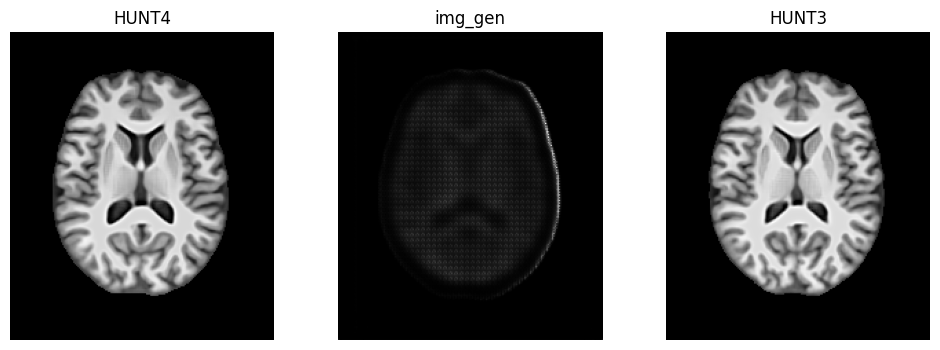

Initializing...:   0%|          | 0/300 [00:00<?, ?it/s]2024-04-03 19:12:27.796619: I external/local_xla/xla/service/service.cc:168] XLA service 0x7f84867d81c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2024-04-03 19:12:27.796659: I external/local_xla/xla/service/service.cc:176]   StreamExecutor device (0): Tesla V100-PCIE-32GB, Compute Capability 7.0
2024-04-03 19:12:32.949729: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1712164355.532709  697929 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
d_loss: 0.49890	g_loss: 0.28134	vmx_loss: 0.30761: 100%|██████████| 300/300 [18:06<00:00,  3.62s/it]  



Epoch 2/50


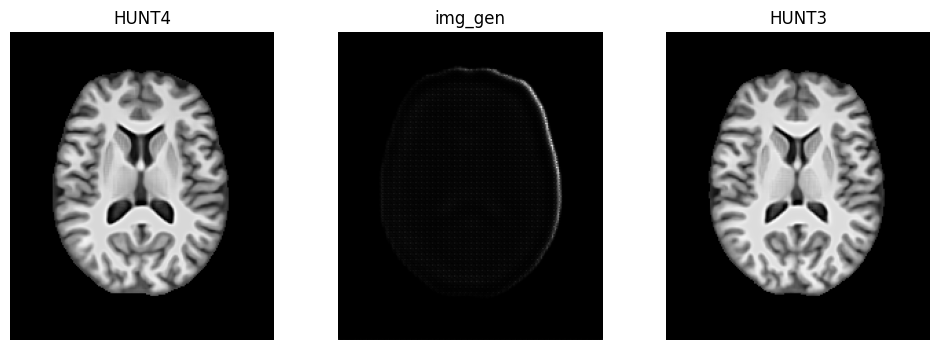

d_loss: 0.49985	g_loss: 0.26410	vmx_loss: 0.29072: 100%|██████████| 300/300 [15:42<00:00,  3.14s/it]



Epoch 3/50


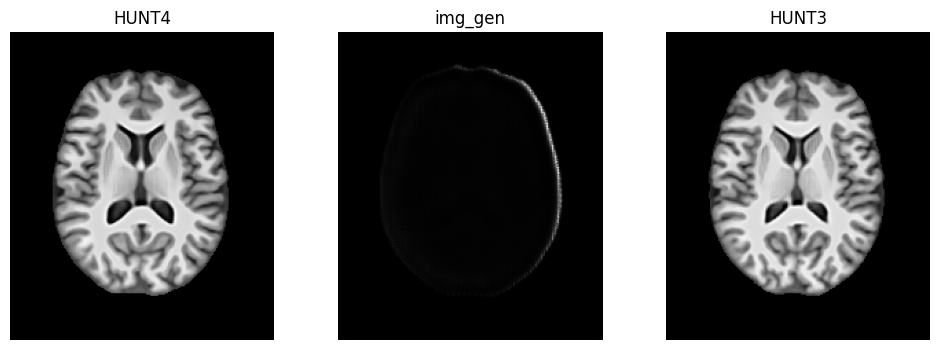

d_loss: 0.49947	g_loss: 0.26608	vmx_loss: 0.29250: 100%|██████████| 300/300 [17:48<00:00,  3.56s/it]



Epoch 4/50


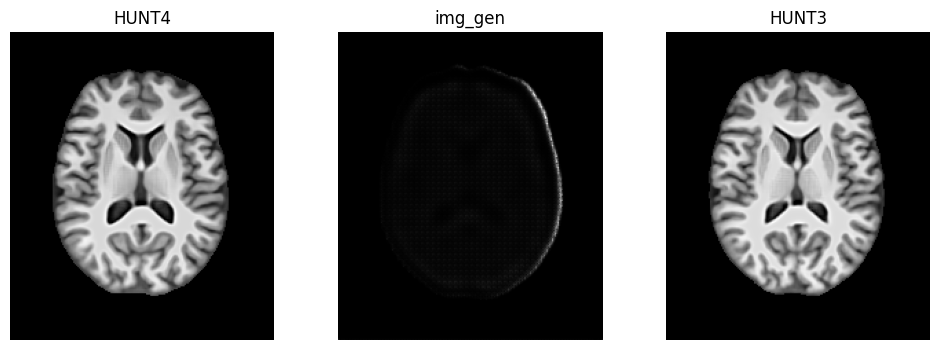

d_loss: 0.49706	g_loss: 0.26216	vmx_loss: 0.28905:   5%|▌         | 15/300 [00:55<16:36,  3.50s/it]

In [7]:

def train(num_epochs, batch_size):
    # input_shape = (193,229,193)
    input_shape = (192,224,192)
    # input_shape = (64,64,64)
    current_plane = 116

    # ---- Models
    G = Generator()
    D = Discriminator()
    VXM = create_vxm_model(input_shape)

    # optimizers
    inital_lr = 1e-4
    vxm_optimizer = tf.keras.optimizers.Adam(inital_lr)
    g_optimizer = tf.keras.optimizers.Adam(inital_lr)
    d_optimizer = tf.keras.optimizers.Adam(inital_lr)

    # ---- Data
    server = True
    data_train = DataLoaderComplete(image_sufix=pil.INAME_PREPROCESSED,
                                    batch_size=batch_size, 
                                    image_size=input_shape, 
                                    channels_first=False,
                                    shuffle=True, 
                                    nb_patients=300, 
                                    shuffle_before_selecting=False, 
                                    server=server)
    # visualization
    nb_loss = 3
    acum_loss_train = udl.AcumulativeMetrics(nb_metrics = nb_loss)

    log_dir=f"{current_path}/models/logs/train"
    summary_writer = tf.summary.create_file_writer(log_dir)

    # ---- checkpoint
    checkpoint_dir = f"{current_path}/models/training_checkpoints/"
    checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
    checkpoint = tf.train.Checkpoint(
                                    g_optimizer=g_optimizer,
                                    d_optimizer=d_optimizer,
                                    vxm_optimizer=vxm_optimizer,
                                    G=G,
                                    D=D,
                                    VXM=VXM)
    # restore checkpoint
    checkpoint.restore(tf.train.latest_checkpoint(checkpoint_dir))

    for epoch in range(0,num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        
        # visualize images
        val_results = show_generated_image("08202", G, input_shape, current_plane=current_plane)

        # ---- Train
        acum_loss_train.reset()
        progress_bar = tqdm(total=len(data_train), desc=f'Initializing...')
        for step, (h3_batch, h4_batch) in enumerate(data_train):
            d_loss, g_loss, vmx_loss = train_step(G, D, VXM, h3_batch, h4_batch, g_optimizer, d_optimizer, vxm_optimizer)
            acum_loss_train.update((d_loss, g_loss, vmx_loss))
            losses_text = acum_loss_train.get_progress_bar_text(['d_loss', 'g_loss', 'vmx_loss'])

            progress_bar.set_description(desc=losses_text)
            progress_bar.update(1)
        del progress_bar

        # ---- Check points
        if  epoch > 0 and epoch % 2 == 0:
            checkpoint.save(file_prefix=checkpoint_prefix)
        
        # ---- Learning rate
        # if epoch > 44 and epoch % 22 == 0:
        if epoch > 10 and epoch % 4 == 0:
            inital_lr *= 0.5
            g_optimizer.learning_rate = inital_lr
            d_optimizer.learning_rate = inital_lr
            vxm_optimizer.learning_rate = inital_lr

        # ---- tensorboard
        loss_mean = acum_loss_train.get_mean()
        with summary_writer.as_default():
            tf.summary.scalar('d_loss', loss_mean[0], step=epoch)
            tf.summary.scalar('g_loss', loss_mean[1], step=epoch)
            tf.summary.scalar('vmx_loss', loss_mean[2], step=epoch)

            # images
            gen_image = np.expand_dims(np.expand_dims(val_results[2], axis=-1), axis=0)
            hunt4_vs_gen = np.expand_dims(np.stack([val_results[2], val_results[1], np.zeros_like(val_results[1])], axis=-1), axis=0)
            tf.summary.image("generated", gen_image, step=epoch)
            tf.summary.image("R: Gen - G: HUNT4", hunt4_vs_gen, step=epoch)
    

train(num_epochs=50, batch_size=1)

In [ ]:
# Sim: 0.00000 	 gen_loss: 0.93415 	 disc_loss: 1.11709: 100%|██████████| 8/8 [00:14<00:00,  1.86s/it]
# Sim: 0.00000 	 gen_loss: 1.22538 	 disc_loss: 1.64933: 100%|██████████| 8/8 [00:14<00:00,  1.86s/it]


